# A Live WiFi Floor Plan from Existing Laws

Render a floor plan, place a router, and predict the signal strength everywhere, using only
established physics:

| § | law | role |
|---|---|---|
| 1 | **Friis transmission equation** → free-space path loss | inverse-square spreading; SymPy shows 6.02 dB per doubling |
| 2 | **multi-wall model** + segment-intersection geometry | each wall crossed costs a fixed dB loss |
| 3 | coverage maps at 2.4 vs. 5 GHz; best router spot | rendering + optimization |
| 4 | **live** router placement | `ipywidgets` slider (run the notebook to use it) |
| 5 | **Wien's law** for skin; why thermal cameras use 8–14 µm | Planck band radiance |

**Scope.** This is *coverage planning* (where should the router go?). It doesn't detect
or track people. Wall losses are typical order-of-magnitude assumptions, and the model ignores
reflections and multipath, so treat maps as first-order estimates. Module:
[`dgs/wifi_floorplan.py`](../dgs/wifi_floorplan.py)

In [ ]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.wifi_floorplan import (
    WALL_LOSS_DB, default_floorplan, friis_symbolic, fspl_db, coverage_map, coverage_fraction,
    best_router_position, wien_peak_um, band_radiance,
)
W, H, walls = default_floorplan()
COLORS = {"concrete": "k", "brick": "#8B4513", "drywall": "0.55", "glass": "deepskyblue", "door (wood)": "peru"}

def draw(ax, P=None, xs=None, ys=None, router=None, title=""):
    if P is not None:
        im = ax.imshow(P, origin="lower", extent=[0, W, 0, H], cmap="turbo", vmin=-90, vmax=-30)
        ax.contour(xs, ys, P, [-67], colors="w", linewidths=1.2)
    for (a, b, m) in walls:
        ax.plot([a[0], b[0]], [a[1], b[1]], color=COLORS[m], lw=3 if m in ("concrete", "brick") else 2)
    if router is not None:
        ax.plot(*router, "w*", ms=16, mec="k")
    ax.set(xlim=(0, W), ylim=(0, H), aspect="equal", title=title, xlabel="x (m)", ylabel="y (m)")
    return im if P is not None else None

# 1. Friis → free-space path loss

Power from an antenna spreads over a sphere, so the received fraction is
$P_r/P_t = G_tG_r(\lambda/4\pi d)^2$. In decibels, that's the **free-space path loss**:

In [ ]:
ratio, fspl, per_doubling, val = friis_symbolic()
display(Math(r"\frac{P_r}{P_t} = " + sp.latex(ratio)))
display(Math(r"\text{FSPL} = " + sp.latex(fspl) + r"\ \text{dB},\qquad \text{FSPL}(2d) - \text{FSPL}(d) = " + sp.latex(per_doubling) + f" = {val:.2f}" + r"\ \text{dB}"))
print(f"FSPL at 1 m: 2.4 GHz {fspl_db(1, 2.4e9):.2f} dB,  5 GHz {fspl_db(1, 5e9):.2f} dB  (5 GHz starts {fspl_db(1,5e9)-fspl_db(1,2.4e9):.1f} dB behind)")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

FSPL at 1 m: 2.4 GHz 40.05 dB,  5 GHz 46.43 dB  (5 GHz starts 6.4 dB behind)


# 2. Walls: the multi-wall model

Draw a straight line from the router to each point and count the walls it crosses (an
*orientation test* on line segments). Each crossing adds its material's loss. These are
**assumed** typical values, and higher frequencies lose more:

,material,loss @ 2.4 GHz (dB),loss @ 5 GHz (dB)
0,drywall,3.0,4.0
1,glass,2.0,3.0
2,brick,8.0,12.0
3,concrete,12.0,20.0
4,door (wood),3.0,4.0


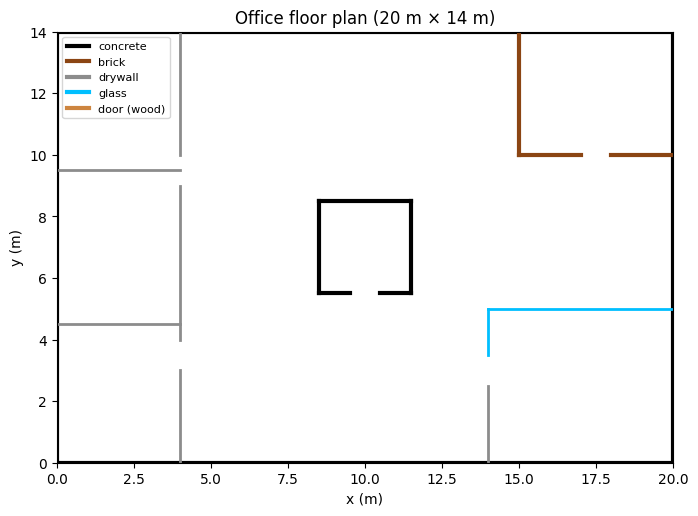

In [ ]:
display(pd.DataFrame([{"material": m, "loss @ 2.4 GHz (dB)": a, "loss @ 5 GHz (dB)": b} for m, (a, b) in WALL_LOSS_DB.items()]))
fig, ax = plt.subplots(figsize=(8, 5.6)); draw(ax, title="Office floor plan (20 m × 14 m)")
for m, c in COLORS.items():
    ax.plot([], [], color=c, lw=3, label=m)
ax.legend(fontsize=8, loc="upper left"); plt.show()

# 3. Coverage maps

$P_r[\text{dBm}] = 20\ \text{dBm} - \text{FSPL}(d) - \sum L_\text{wall}$. The white contour is
−67 dBm, a common "good signal" threshold for video calls.

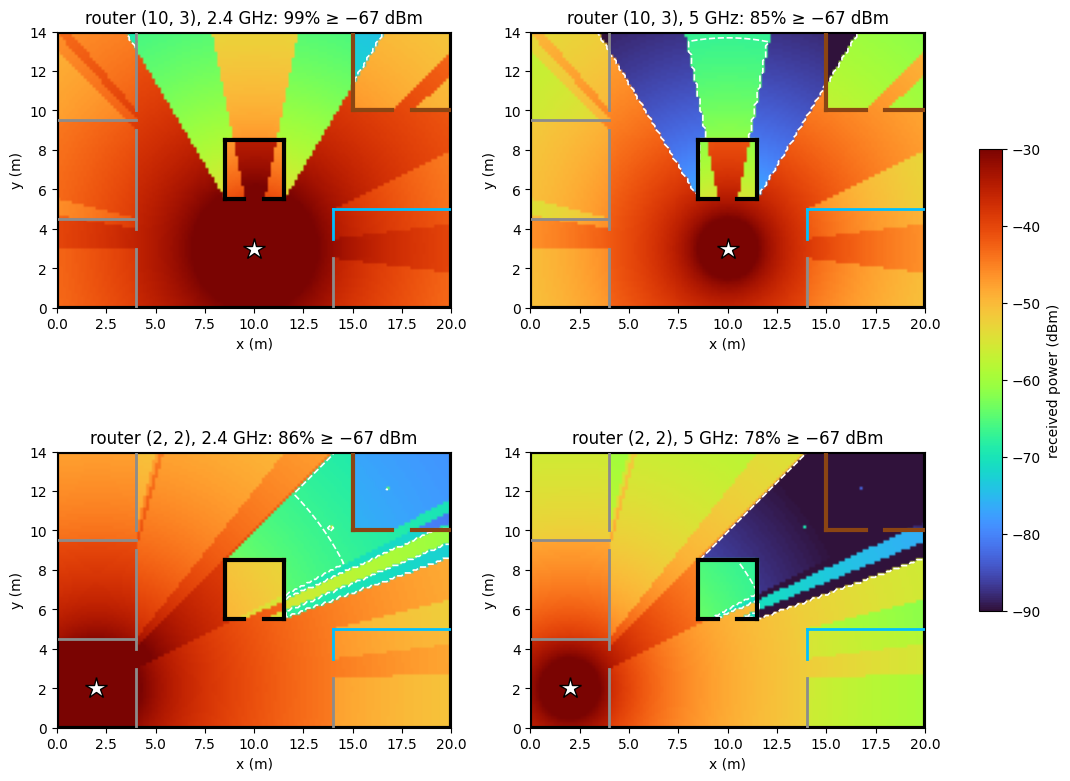

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, router in zip(axes, ((10, 3), (2, 2))):
    for ax, f in zip(row, (2.4e9, 5e9)):
        xs, ys, P = coverage_map(router, walls, W, H, f, res=0.15)
        im = draw(ax, P, xs, ys, router, f"router {router}, {f/1e9:g} GHz: {100*coverage_fraction(P):.0f}% ≥ −67 dBm")
fig.colorbar(im, ax=axes, shrink=0.6, label="received power (dBm)")
plt.show()

In [ ]:
for f in (2.4e9, 5e9):
    pos, frac = best_router_position(walls, W, H, f)
    print(f"{f/1e9:g} GHz: best grid spot {pos} → {100*frac:.0f}% coverage")

2.4 GHz: best grid spot (9.5, 6.5) → 100% coverage


5 GHz: best grid spot (9.5, 0.5) → 88% coverage


**Reading the maps.**
- 5 GHz loses about 6.4 dB more in free space *and* more per wall. It's faster but has shorter
  range, which is why mesh systems and dual-band routers exist.
- The **concrete core** casts a deep shadow at 5 GHz. A central router beats a corner one.
- At 2.4 GHz **many spots tie at 100%** on this floor. The search just returns the first one it
  finds, which here sits inside the stairwell core. Read it as "anywhere central works", not as
  one magic spot. At 5 GHz the best spot reaches about 88% coverage: one access point isn't
  enough.

# 4. Live: move the router

Run this cell in Jupyter (not in a static view) and drag the sliders. The map recomputes from
the same laws:

In [ ]:
try:
    import ipywidgets as widgets
    @widgets.interact(x=widgets.FloatSlider(value=10, min=0.5, max=W-0.5, step=0.5),
                      y=widgets.FloatSlider(value=3, min=0.5, max=H-0.5, step=0.5),
                      band=widgets.ToggleButtons(options=[("2.4 GHz", 2.4e9), ("5 GHz", 5e9)]))
    def live(x, y, band):
        xs, ys, P = coverage_map((x, y), walls, W, H, band, res=0.25)
        fig, ax = plt.subplots(figsize=(8, 5.6))
        im = draw(ax, P, xs, ys, (x, y), f"{band/1e9:g} GHz: {100*coverage_fraction(P):.0f}% ≥ −67 dBm")
        fig.colorbar(im, ax=ax, label="dBm"); plt.show()
except ImportError:
    print("ipywidgets not installed in this kernel — `pip install ipywidgets` for the live slider")

interactive(children=(FloatSlider(value=10.0, description='x', max=19.5, min=0.5, step=0.5), FloatSlider(value…

# 5. Thermal imaging: Wien's law for skin

The exercise from the last notebook: a 10 µm peak means $T = b/\lambda = 290$ K. Going the other
way, real skin at about 306 K (33 °C) peaks at 9.5 µm. Thermal cameras use the **8–14 µm
long-wave IR band**. It sits right on top of that peak, *and* the atmosphere is transparent there.
This is a separate electromagnetic band from WiFi: WiFi wavelengths are 6–12.5 **cm**, about
10,000× longer.

In [ ]:
rows = []
for name, T, eps in (("skin", 306.0, 0.98), ("room wall", 293.0, 0.95), ("hot coffee", 343.0, 0.95)):
    rows.append({"object": name, "T (K)": T, "Wien peak (µm)": round(wien_peak_um(T), 2),
                 "8–14 µm radiance (W/m²/sr)": round(band_radiance(T, emissivity=eps), 2)})
display(pd.DataFrame(rows))
print(f"10 µm peak → T = {2.8977719551851727e-3/10e-6:.1f} K;   WiFi λ: 2.4 GHz = {299792458/2.4e9*100:.1f} cm, 5 GHz = {299792458/5e9*100:.1f} cm")

,object,T (K),Wien peak (µm),8–14 µm radiance (W/m²/sr)
0,skin,306.0,9.47,58.90
1,room wall,293.0,9.89,46.79
2,hot coffee,343.0,8.45,93.17


10 µm peak → T = 289.8 K;   WiFi λ: 2.4 GHz = 12.5 cm, 5 GHz = 6.0 cm


Skin is only about 13 K warmer than the wall, but in the 8–14 µm band it's about 25% brighter.
That contrast is what a thermal camera displays.

## Exercises
1. Add a second access point and plot the **maximum** of the two maps. Where should it go for 5 GHz?
2. Change the brick restroom walls to concrete. How much does the north-east corner lose?
3. Verify the 6.02 dB-per-doubling law by sampling the map along an open line from the router.
4. Why can't one formula, Friis, predict signal behind a metal filing cabinet? What physics is missing?